In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, precision_recall_curve
from imblearn.over_sampling import SMOTE
import xgboost as xgb
import shap
import mlflow
import mlflow.sklearn
import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

df = pd.read_csv('data/creditcard.csv')
print(f"Dataset shape: {df.shape}")
print(f"Fraud percentage: {df['Class'].mean()*100:.3f}%")

Dataset shape: (284807, 31)
Fraud percentage: 0.173%


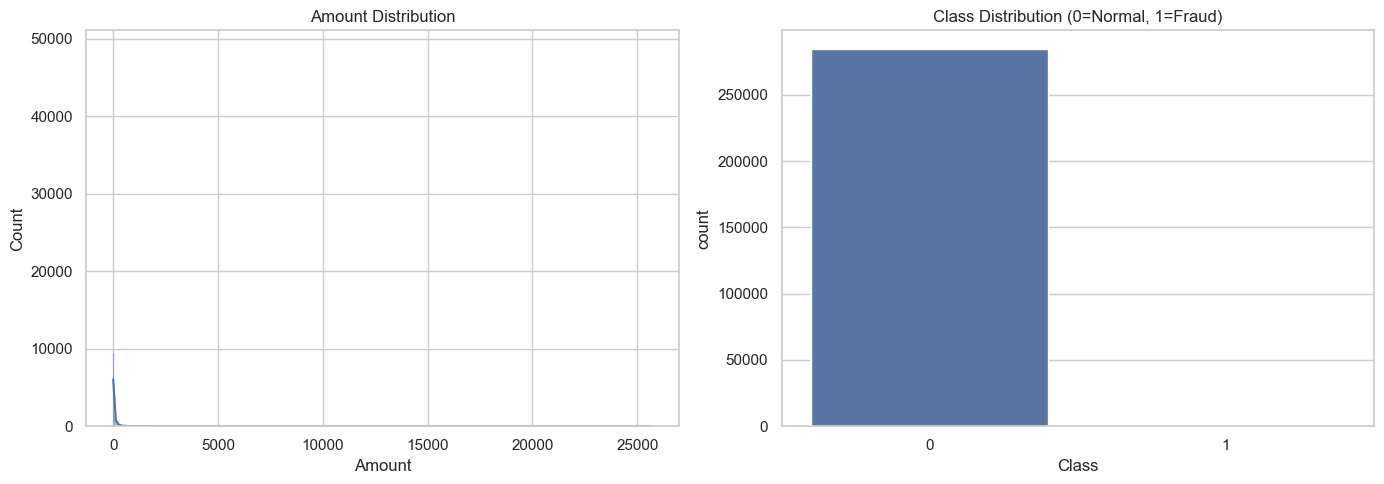

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['Amount'], kde=True, ax=axes[0])
axes[0].set_title('Amount Distribution')
sns.countplot(x='Class', data=df, ax=axes[1])
axes[1].set_title('Class Distribution (0=Normal, 1=Fraud)')
plt.tight_layout()
plt.show()

In [4]:
X = df.drop(columns=['Class', 'Time'])
y = df['Class']

scaler = StandardScaler()
X['Amount'] = scaler.fit_transform(X[['Amount']])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print(f"Train size: {len(X_train)}, Test size: {len(X_test)}")

Train size: 199364, Test size: 85443


In [5]:
model_lr = LogisticRegression(max_iter=1000, random_state=42)
model_lr.fit(X_train, y_train)
pred_proba_lr = model_lr.predict_proba(X_test)[:, 1]

print("Logistic Regression AUC-ROC:", roc_auc_score(y_test, pred_proba_lr))

Logistic Regression AUC-ROC: 0.9564924118678735


In [6]:
smote = SMOTE(random_state=42, sampling_strategy=0.2)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

model_rf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
model_rf.fit(X_train_smote, y_train_smote)
pred_proba_rf = model_rf.predict_proba(X_test)[:, 1]

print("Random Forest + SMOTE AUC-ROC:", roc_auc_score(y_test, pred_proba_rf))

Random Forest + SMOTE AUC-ROC: 0.9776239220638071


In [7]:
model_xgb = xgb.XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, scale_pos_weight=500, random_state=42, eval_metric='auc')
model_xgb.fit(X_train_smote, y_train_smote)
pred_proba_xgb = model_xgb.predict_proba(X_test)[:, 1]

print("XGBoost + SMOTE AUC-ROC:", roc_auc_score(y_test, pred_proba_xgb))

XGBoost + SMOTE AUC-ROC: 0.9612764443909294


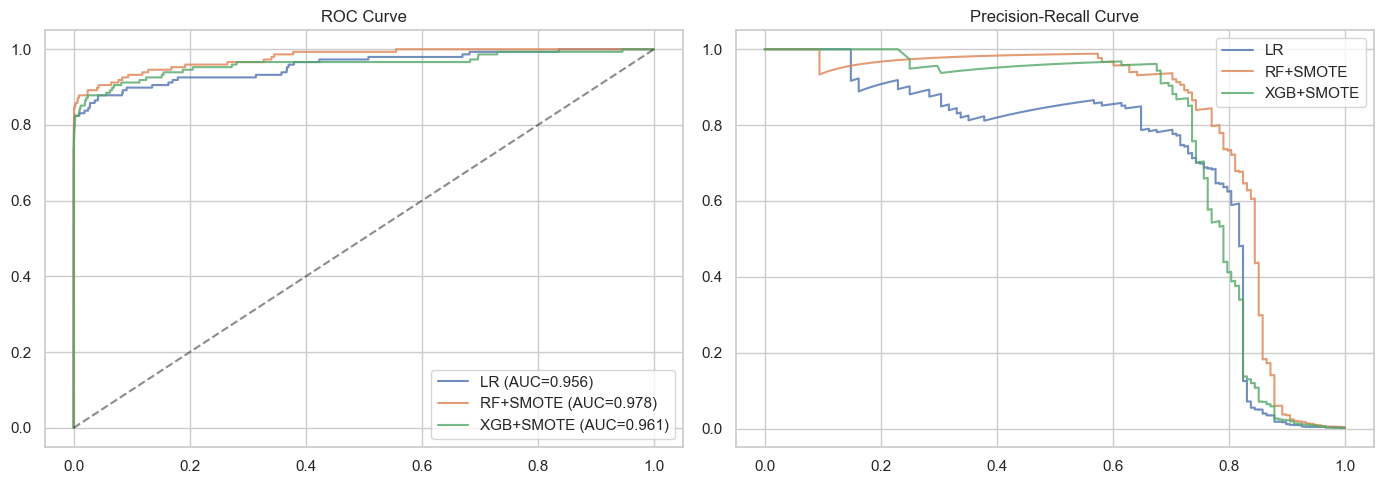

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, proba in [('LR', pred_proba_lr), ('RF+SMOTE', pred_proba_rf), ('XGB+SMOTE', pred_proba_xgb)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_test, proba):.3f})', alpha=0.8)
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].set_title('ROC Curve')
axes[0].legend()

for name, proba in [('LR', pred_proba_lr), ('RF+SMOTE', pred_proba_rf), ('XGB+SMOTE', pred_proba_xgb)]:
    precision, recall, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(recall, precision, label=name, alpha=0.8)
axes[1].set_title('Precision-Recall Curve')
axes[1].legend()

plt.tight_layout()
plt.show()

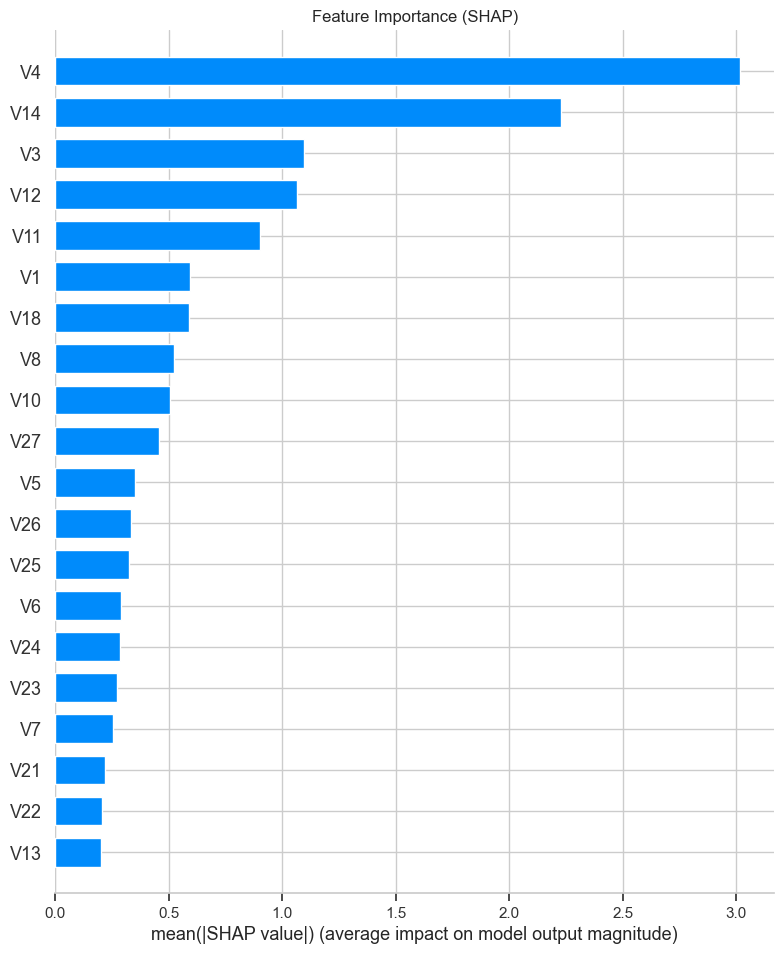

In [9]:
explainer = shap.TreeExplainer(model_xgb)
shap_values = explainer.shap_values(X_test)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, plot_type="bar", show=False)
plt.title('Feature Importance (SHAP)')
plt.show()

In [10]:
mlflow.set_experiment("Fraud_Detection_Comparison")

with mlflow.start_run(run_name="XGBoost_SMOTE_Best"):
    mlflow.log_param("model", "XGBoost")
    mlflow.log_param("sampling", "SMOTE (0.2)")
    mlflow.log_metric("AUC-ROC", roc_auc_score(y_test, pred_proba_xgb))
    mlflow.log_metric("Precision", classification_report(y_test, model_xgb.predict(X_test), output_dict=True)['1']['precision'])
    mlflow.log_metric("Recall", classification_report(y_test, model_xgb.predict(X_test), output_dict=True)['1']['recall'])
    mlflow.sklearn.log_model(model_xgb, "xgboost_model")
    print("MLflow run logged successfully.")

2026/11/02 10:00:11 INFO mlflow.tracking.fluent: Experiment with name 'Fraud_Detection_Comparison' does not exist. Creating a new experiment.


MLflow run logged successfully.
